# Symmetry of the MnBi₂Te₄ models (paper `tab:symmetry-mbt`)

Do the Wannier models behind ∂θ/∂Q obey the magnetic point group of their structure? Production window
`f10.962_w12.810_k8`; the models are built exactly as in the production c2 jobs (`axion_phonon.wannier.pair_models`:
H and A(R) from the `.chk`, folded on the base centres' nearest atoms, one τ for both). The functions are
`axion_phonon/symmetry.py`; the group theory behind the groups is `MBT Symmetry Analysis.md` in this folder.

**The groups** are read from each structure's pw.x output, with QE's Cartesian matrices and 'Time Reversal' flags:
- **Undistorted:** QE lists 12 operations and disables fractional translations for the magnetic supercell, so it
  does not list the anti-translation {1′|½,½,½} that exchanges the septuple layers. Its products with the 12 are the
  same matrices with the opposite priming. Added here (`ANTI_TRANSLATION`), this gives 24 operations: −3m1′, the
  magnetic point group of $R_I\bar3c$.
- **Displaced (T₂⁻ patterns):** the displacement breaks the anti-translation. QE lists all 12 operations of −3′m′,
  6 of them with a fractional translation.

**Three tests per model:**
1. DFT eigenvalues on the 8³ Wannier mesh: e_n(g k) = e_n(k) (k → −g k for a primed g), for the bands below the
   frozen-window top. This needs only the `.eig` and `.win`, so it runs here for every structure. It also checks the
   groups themselves.
2. Interpolated bands at the test k points.
3. Curvature. PT forces Tr F = 0 in every structure, so the Berry curvature itself would compare zero with zero. The
   test uses the gauge-invariant tensor T_ab = Re Tr[F_a F_b] of the 82 occupied bands (F_a = ε_abc Ω_bc/2,
   Cartesian), which must satisfy T(g k) = R T(k) Rᵀ for every g, separately for each part of eq (24) (internal,
   cross, external) and for their sum.

**Controls**, which must fail: C₄z (not a symmetry of the lattice), and plain inversion k → −k, the operation the
displacement breaks (a symmetry of the base, so a control only for the displaced structures).

**Which models run here:** the `.chk` of the base and of pattern 3 are in `data/` (about 2.5 min, 4 GB). Patterns 1, 2
and 4 run on the cluster (`tests/symmetry/run_mbt_symmetry.sh`); their results are loaded below when copied to
`data/`.

In [1]:
# ---- settings
from pathlib import Path
DATA = Path("/Users/treycole/Repos/axion-phonon/data/MnBi2Te4")
WINDOW = DATA / "windows/f10.962_w12.810_k8"                      # production Wannier runs: WINDOW/<structure>/out
DFT = DATA / "dft"                                                 # pw.x outputs: DFT/<structure>/scf/out/MnBi2Te4.scf.out
STRUCTURES = ["T2-_p1_Q0.01", "T2-_p2_Q0.01", "T2-_p3_Q0.01", "T2-_p4_Q0.01", "T2-_p3_Q0.03"]
LOCAL_PAIR = "T2-_p3_Q0.01"         # the displaced structure whose .chk is local: models built here, with the base
CLUSTER = WINDOW                    # cluster results: CLUSTER/symmetry_<structure>/out/symmetry_{base,mode}.npz
PREFIX = "MnBi2Te4"
ANTI_TRANSLATION = True             # the base also has {1'|1/2,1/2,1/2}, which QE does not list
N_OCC = 82
FROZEN_TOP = 10.962                 # eV, dis_froz_max: test 1 over the bands below it at every k
N_GENERIC = 7                       # random k (Cartesian components uniform in +-GENERIC_HALF_WIDTH)
GENERIC_HALF_WIDTH = 0.23           # 1/A
N_TUBE = 5                          # k near the k_z axis, where dtheta/dQ sits
TUBE_RADIUS = 0.02                  # 1/A
SEED = 20260825                     # as the 10-22 run: the same k
THRESHOLDS = {"dft_ueV": 1.0, "bands_meV": 1e-3, "internal": 1e-6, "cross": 5e-3, "external": 5e-3, "total": 1e-3,
              "control_min": 5e-3, "control_over_residual": 10}   # maxima over the operations other than the identity
SAVE = WINDOW / "symmetry"          # summary.csv and one npz per model (read by tests/regression); None to skip
# ---------------


In [2]:
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "/Users/treycole/Repos/axion-phonon")
from axion_phonon import symmetry, wannier
from axion_phonon.io import wannier90

pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_colwidth", 60)
CONTROLS = (("C4z", np.array([[0.0, -1, 0], [1, 0, 0], [0, 0, 1]]), False), ("-E unprimed", -np.eye(3), False))


def mesh_run(folder):
    """What test 1 needs from a Wannier run without its .chk: the mesh (.win kpoints), the .eig and the cell."""
    win = wannier90.read_win(folder / f"{PREFIX}.win")
    text = (folder / f"{PREFIX}.win").read_text().lower()
    block = text.split("begin kpoints")[1].split("end kpoints")[0]
    kpts = np.array([l.split()[:3] for l in block.strip().splitlines()], float)
    return {"kpts": kpts, "energies": wannier90.read_eig(folder / f"{PREFIX}.eig", len(kpts)),
            "reciprocal": 2 * np.pi * np.linalg.inv(win["lattice"]).T, "mp_grid": win["mp_grid"]}


def matrix_text(R):
    return " / ".join(" ".join(f"{x:+.3f}".replace("+0.000", " 0") for x in row) for row in R)


## The groups

One table per group: the operations as QE lists them (QE's name, then T if primed), the Cartesian matrix by rows, its
determinant (−1: improper), and where it comes from. All displaced structures have the same group; the cell checks
that and shows it once.

In [3]:
groups = {"base": symmetry.group(DFT / "base/scf/out" / f"{PREFIX}.scf.out", ANTI_TRANSLATION)}
for s in STRUCTURES:
    groups[s] = symmetry.group(DFT / s / "scf/out" / f"{PREFIX}.scf.out")
ref = groups[STRUCTURES[0]]
for s in STRUCTURES[1:]:
    assert np.allclose(groups[s][0], ref[0]) and np.array_equal(groups[s][1], ref[1]), f"{s}: a different group"


def group_table(ops, primed, names, listed):
    return pd.DataFrame({"operation": names, "R (Cartesian, by rows)": [matrix_text(R) for R in ops],
                         "det": np.rint(np.linalg.det(ops)).astype(int), "primed": primed,
                         "source": np.where(listed, "QE", "QE x {1'|t}")})


for label, g in (("undistorted structure", groups["base"]), ("displaced structures (all patterns)", ref)):
    ctrl = symmetry.controls(g[0], g[1], CONTROLS)
    print(f"{label}: {len(g[0])} operations, {int(g[1].sum())} primed; controls: {[c[0] for c in ctrl]}")
    display(group_table(*g))


undistorted structure: 24 operations, 12 primed; controls: ['C4z']


,operation,"R (Cartesian, by rows)",det,primed,source
0,identity,+1.000 0 0 / 0 +1.000 0 / 0 0 +1.000,1,False,QE
1,"180 deg rotation - cart. axis [1,0,0] T",+1.000 0 0 / 0 -1.000 0 / 0 0 -1.000,1,True,QE
2,"120 deg rotation - cryst. axis [0,0,1]",-0.500 -0.866 0 / +0.866 -0.500 0 / 0 0 +1.000,1,False,QE
3,"120 deg rotation - cryst. axis [0,0,-1]",-0.500 +0.866 0 / -0.866 -0.500 0 / 0 0 +1.000,1,False,QE
4,"180 deg rotation - cryst. axis [0,1,0] T",-0.500 -0.866 0 / -0.866 +0.500 0 / 0 0 -1.000,1,True,QE
5,"180 deg rotation - cryst. axis [1,1,0] T",-0.500 +0.866 0 / +0.866 +0.500 0 / 0 0 -1.000,1,True,QE
6,inversion,-1.000 0 0 / 0 -1.000 0 / 0 0 -1.000,-1,False,QE
7,"inv. 180 deg rotation - cart. axis [1,0,0] T",-1.000 0 0 / 0 +1.000 0 / 0 0 +1.000,-1,True,QE
8,"inv. 120 deg rotation - cryst. axis [0,0,1]",+0.500 +0.866 0 / -0.866 +0.500 0 / 0 0 -1.000,-1,False,QE
9,"inv. 120 deg rotation - cryst. axis [0,0,-1]",+0.500 -0.866 0 / +0.866 +0.500 0 / 0 0 -1.000,-1,False,QE


displaced structures (all patterns): 12 operations, 6 primed; controls: ['C4z', '-E unprimed']


,operation,"R (Cartesian, by rows)",det,primed,source
0,identity,+1.000 0 0 / 0 +1.000 0 / 0 0 +1.000,1,False,QE
1,"180 deg rotation - cart. axis [1,0,0]",+1.000 0 0 / 0 -1.000 0 / 0 0 -1.000,1,False,QE
2,"120 deg rotation - cryst. axis [0,0,1]",-0.500 -0.866 0 / +0.866 -0.500 0 / 0 0 +1.000,1,False,QE
3,"120 deg rotation - cryst. axis [0,0,-1]",-0.500 +0.866 0 / -0.866 -0.500 0 / 0 0 +1.000,1,False,QE
4,"180 deg rotation - cryst. axis [0,1,0]",-0.500 -0.866 0 / -0.866 +0.500 0 / 0 0 -1.000,1,False,QE
5,"180 deg rotation - cryst. axis [1,1,0]",-0.500 +0.866 0 / +0.866 +0.500 0 / 0 0 -1.000,1,False,QE
6,inversion T,-1.000 0 0 / 0 -1.000 0 / 0 0 -1.000,-1,True,QE
7,"inv. 180 deg rotation - cart. axis [1,0,0] T",-1.000 0 0 / 0 +1.000 0 / 0 0 +1.000,-1,True,QE
8,"inv. 120 deg rotation - cryst. axis [0,0,1] T",+0.500 +0.866 0 / -0.866 +0.500 0 / 0 0 -1.000,-1,True,QE
9,"inv. 120 deg rotation - cryst. axis [0,0,-1] T",+0.500 -0.866 0 / +0.866 +0.500 0 / 0 0 -1.000,-1,True,QE


## The k points

The same k as the 10-22 run (same seed and order). "generic": Cartesian components uniform in ±0.23 Å⁻¹. Along k_z
this spans about two zone heights (Z is at 0.115 Å⁻¹), but in-plane the zone reaches about 0.84 Å⁻¹, so these points
cover the inner part of the in-plane zone. "tube": within 0.02 Å⁻¹ of the k_z axis, between Γ and Z, where the
integrand of ∂θ/∂Q sits.

,set,#,k reduced,k Cartesian (1/A),k_perp (1/A),k_z / |Gamma Z|
0,generic,0,"[-0.1012, -0.1413, -0.1812]","[0.1161, -0.0002, -0.0325]",0.1161,-0.282
1,generic,1,"[-0.7381, -0.8574, -0.722]","[-0.0233, -0.2132, -0.1779]",0.2144,-1.545
2,generic,2,"[0.7849, 0.8546, 0.6987]","[0.125, 0.1889, 0.1795]",0.2265,1.559
3,generic,3,"[-0.8133, -0.6336, -0.7052]","[-0.1568, 0.2103, -0.1652]",0.2624,-1.435
4,generic,4,"[0.2569, 0.2469, 0.2621]","[-0.0075, -0.0211, 0.0588]",0.0224,0.511
5,generic,5,"[0.4841, 0.5661, 0.5628]","[-0.1141, 0.0714, 0.1238]",0.1346,1.075
6,generic,6,"[-0.2317, -0.3552, -0.3193]","[0.1269, -0.1334, -0.0696]",0.1842,-0.604
7,tube,0,"[0.2368, 0.2475, 0.2437]","[-0.0101, 0.0122, 0.0559]",0.0158,0.485
8,tube,1,"[0.0604, 0.0659, 0.0624]","[-0.0029, 0.0075, 0.0145]",0.0080,0.126
9,tube,2,"[0.104, 0.0928, 0.0973]","[0.0098, -0.0132, 0.0226]",0.0164,0.196


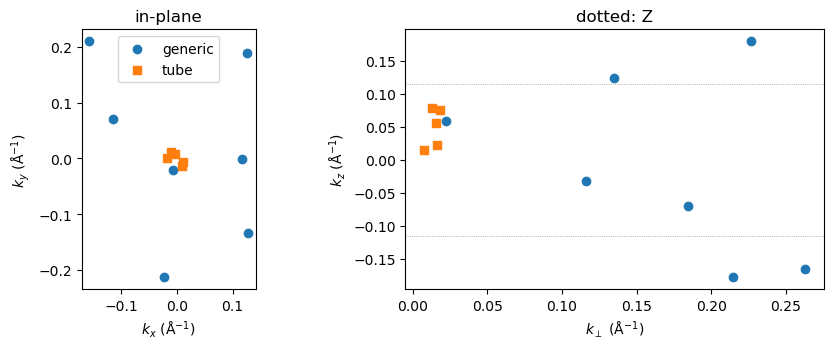

In [4]:
reciprocal = mesh_run(WINDOW / "base/out")["reciprocal"]
rng = np.random.default_rng(SEED)
ksets = {"generic": symmetry.random_k(reciprocal, N_GENERIC, GENERIC_HALF_WIDTH, rng),
         "tube": symmetry.near_axis_k(reciprocal, N_TUBE, TUBE_RADIUS, rng)}
z_height = np.linalg.norm(reciprocal.sum(0)) / 2                   # |Gamma Z|, 1/A
rows = []
for kset, k in ksets.items():
    for i, (kr, kc) in enumerate(zip(k, k @ reciprocal)):
        rows.append({"set": kset, "#": i, "k reduced": np.round(kr, 4), "k Cartesian (1/A)": np.round(kc, 4),
                     "k_perp (1/A)": round(float(np.hypot(*kc[:2])), 4), "k_z / |Gamma Z|": round(float(kc[2] / z_height), 3)})
display(pd.DataFrame(rows))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))
for kset, mk in (("generic", "o"), ("tube", "s")):
    kc = ksets[kset] @ reciprocal
    a1.scatter(kc[:, 0], kc[:, 1], marker=mk, label=kset)
    a2.scatter(np.hypot(kc[:, 0], kc[:, 1]), kc[:, 2], marker=mk, label=kset)
a1.set(xlabel=r"$k_x$ (Å$^{-1}$)", ylabel=r"$k_y$ (Å$^{-1}$)", aspect="equal", title="in-plane")
a2.axhline(z_height, color="0.6", lw=0.6, ls=":"); a2.axhline(-z_height, color="0.6", lw=0.6, ls=":")
a2.set(xlabel=r"$k_\perp$ (Å$^{-1}$)", ylabel=r"$k_z$ (Å$^{-1}$)", title="dotted: Z")
a1.legend(); fig.tight_layout(); plt.show()


## Test 1: DFT eigenvalues on the mesh

The largest |e_n(g k) − e_n(k)| over the 512 mesh points, per operation, for the bands below the frozen-window top at
every k (the bands the Wannier models reproduce) and, for information, for all 240 (the topmost converge less
tightly in the NSCF).

In [5]:
dft = {}
for s in ["base"] + STRUCTURES:
    run = mesh_run(WINDOW / s / "out")
    n_low = int(np.argmax(run["energies"].max(0) > FROZEN_TOP))
    ops, primed, names, listed = groups[s]
    dft[s] = symmetry.dft_residuals(run, ops, primed, n_low)
    print(f"{s:14s}: {len(ops) - 1} operations besides the identity, {n_low} bands below {FROZEN_TOP} eV: "
          f"max {dft[s][1:, 0].max():.2f} ueV (all {run['energies'].shape[1]} bands: {dft[s][1:, 1].max():.2f} ueV)")
display(pd.DataFrame({"operation": groups["base"][2], "base (ueV)": dft["base"][:, 0].round(3)}))
display(pd.DataFrame({"operation": ref[2], **{f"{s} (ueV)": dft[s][:, 0].round(3) for s in STRUCTURES}}))


base          : 23 operations besides the identity, 168 bands below 10.962 eV: max 0.06 ueV (all 240 bands: 28.40 ueV)
T2-_p1_Q0.01  : 11 operations besides the identity, 168 bands below 10.962 eV: max 0.06 ueV (all 240 bands: 20.83 ueV)
T2-_p2_Q0.01  : 11 operations besides the identity, 168 bands below 10.962 eV: max 0.05 ueV (all 240 bands: 4.01 ueV)
T2-_p3_Q0.01  : 11 operations besides the identity, 168 bands below 10.962 eV: max 0.06 ueV (all 240 bands: 11.84 ueV)
T2-_p4_Q0.01  : 11 operations besides the identity, 168 bands below 10.962 eV: max 0.06 ueV (all 240 bands: 14.75 ueV)
T2-_p3_Q0.03  : 11 operations besides the identity, 168 bands below 10.962 eV: max 0.04 ueV (all 240 bands: 11.00 ueV)


,operation,base (ueV)
0,identity,0.000
1,"180 deg rotation - cart. axis [1,0,0] T",0.000
2,"120 deg rotation - cryst. axis [0,0,1]",0.056
3,"120 deg rotation - cryst. axis [0,0,-1]",0.056
4,"180 deg rotation - cryst. axis [0,1,0] T",0.056
5,"180 deg rotation - cryst. axis [1,1,0] T",0.056
6,inversion,0.063
7,"inv. 180 deg rotation - cart. axis [1,0,0] T",0.063
8,"inv. 120 deg rotation - cryst. axis [0,0,1]",0.043
9,"inv. 120 deg rotation - cryst. axis [0,0,-1]",0.043


,operation,T2-_p1_Q0.01 (ueV),T2-_p2_Q0.01 (ueV),T2-_p3_Q0.01 (ueV),T2-_p4_Q0.01 (ueV),T2-_p3_Q0.03 (ueV)
0,identity,0.000,0.000,0.000,0.000,0.000
1,"180 deg rotation - cart. axis [1,0,0]",0.057,0.046,0.056,0.044,0.035
2,"120 deg rotation - cryst. axis [0,0,1]",0.061,0.051,0.062,0.057,0.045
3,"120 deg rotation - cryst. axis [0,0,-1]",0.061,0.051,0.062,0.057,0.045
4,"180 deg rotation - cryst. axis [0,1,0]",0.046,0.045,0.047,0.044,0.044
5,"180 deg rotation - cryst. axis [1,1,0]",0.047,0.045,0.044,0.045,0.044
6,inversion T,0.000,0.000,0.000,0.000,0.000
7,"inv. 180 deg rotation - cart. axis [1,0,0] T",0.057,0.046,0.056,0.044,0.035
8,"inv. 120 deg rotation - cryst. axis [0,0,1] T",0.061,0.051,0.062,0.057,0.045
9,"inv. 120 deg rotation - cryst. axis [0,0,-1] T",0.061,0.051,0.062,0.057,0.045


## Tests 2 and 3: bands and curvature, base and pattern 3

Per operation and per k set: the largest band change (meV) and the curvature residuals per part. Row 0 is the
identity (zeros: a check of the bookkeeping); the controls come last.

In [6]:
t0 = time.time()
base_run = wannier90.read_run(WINDOW / "base/out", PREFIX)
mode_run = wannier90.read_run(WINDOW / LOCAL_PAIR / "out", PREFIX)
models = dict(zip(("base", LOCAL_PAIR), wannier.pair_models(base_run, mode_run, log=lambda s: None)))
print(f"models in {time.time() - t0:.0f} s")
COLUMNS = ["bands (meV)"] + [f"{p}" for p in symmetry.PARTS]
results = {}
for label, model in models.items():
    ops, primed, names, listed = groups[label]
    ctrl = symmetry.controls(ops, primed, CONTROLS)
    cases = list(zip(names, ops, primed)) + [("control " + c[0], c[1], c[2]) for c in ctrl]
    results[label] = {"names": np.array([c[0] for c in cases]), "n_ops": len(ops), "dft_ueV": dft[label]}
    for kset, k in ksets.items():
        rows, X0 = symmetry.table(model, k, reciprocal, cases, N_OCC, "tensor")
        results[label][kset] = rows
        results[label][f"trace_{kset}"] = 0.0
        print(f"\n{label}, {kset} k ({len(k)}): |T| scale " + ", ".join(f"{p} {np.abs(X0[p]).max():.3e}" for p in symmetry.PARTS))
        df = pd.DataFrame(rows, columns=COLUMNS, index=[c[0] for c in cases])
        display(df.style.format({"bands (meV)": "{:.1e}", **{p: "{:.4%}" for p in symmetry.PARTS}}))


models in 123 s



base, generic k (7): |T| scale internal 9.601e+04, cross 3.258e+02, external 3.371e+01, total 9.599e+04


,bands (meV),internal,cross,external,total
identity,2.1e-11,0.0000%,0.0000%,0.0000%,0.0000%
"180 deg rotation - cart. axis [1,0,0] T",1.2e-06,0.0000%,0.0000%,0.0000%,0.0000%
"120 deg rotation - cryst. axis [0,0,1]",6.8e-05,0.0000%,0.0205%,0.1175%,0.0042%
"120 deg rotation - cryst. axis [0,0,-1]",6.3e-05,0.0000%,0.0214%,0.1290%,0.0059%
"180 deg rotation - cryst. axis [0,1,0] T",6.8e-05,0.0000%,0.0205%,0.1175%,0.0042%
"180 deg rotation - cryst. axis [1,1,0] T",6.3e-05,0.0000%,0.0214%,0.1290%,0.0059%
inversion,6.4e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 180 deg rotation - cart. axis [1,0,0] T",6.4e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 120 deg rotation - cryst. axis [0,0,1]",3.6e-05,0.0000%,0.0205%,0.1175%,0.0042%
"inv. 120 deg rotation - cryst. axis [0,0,-1]",4.4e-05,0.0000%,0.0214%,0.1290%,0.0059%



base, tube k (5): |T| scale internal 1.947e+05, cross 3.430e+02, external 3.566e+01, total 1.966e+05


,bands (meV),internal,cross,external,total
identity,2.5e-11,0.0000%,0.0000%,0.0000%,0.0000%
"180 deg rotation - cart. axis [1,0,0] T",3.5e-07,0.0000%,0.0000%,0.0000%,0.0000%
"120 deg rotation - cryst. axis [0,0,1]",4.0e-05,0.0000%,0.0083%,0.1481%,0.0038%
"120 deg rotation - cryst. axis [0,0,-1]",2.2e-05,0.0000%,0.0104%,0.1479%,0.0038%
"180 deg rotation - cryst. axis [0,1,0] T",4.0e-05,0.0000%,0.0083%,0.1481%,0.0038%
"180 deg rotation - cryst. axis [1,1,0] T",2.2e-05,0.0000%,0.0104%,0.1479%,0.0038%
inversion,3.6e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 180 deg rotation - cart. axis [1,0,0] T",3.6e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 120 deg rotation - cryst. axis [0,0,1]",1.7e-05,0.0000%,0.0083%,0.1481%,0.0038%
"inv. 120 deg rotation - cryst. axis [0,0,-1]",2.3e-05,0.0000%,0.0104%,0.1479%,0.0038%



T2-_p3_Q0.01, generic k (7): |T| scale internal 9.599e+04, cross 3.276e+02, external 3.379e+01, total 9.598e+04


,bands (meV),internal,cross,external,total
identity,2.5e-11,0.0000%,0.0000%,0.0000%,0.0000%
"180 deg rotation - cart. axis [1,0,0]",5.2e-05,0.0000%,0.0000%,0.0000%,0.0000%
"120 deg rotation - cryst. axis [0,0,1]",4.7e-05,0.0000%,0.0211%,0.1167%,0.0042%
"120 deg rotation - cryst. axis [0,0,-1]",5.8e-05,0.0000%,0.0219%,0.1292%,0.0059%
"180 deg rotation - cryst. axis [0,1,0]",4.7e-05,0.0000%,0.0211%,0.1167%,0.0042%
"180 deg rotation - cryst. axis [1,1,0]",3.8e-05,0.0000%,0.0219%,0.1292%,0.0059%
inversion T,2.5e-11,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 180 deg rotation - cart. axis [1,0,0] T",5.2e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 120 deg rotation - cryst. axis [0,0,1] T",4.7e-05,0.0000%,0.0211%,0.1167%,0.0042%
"inv. 120 deg rotation - cryst. axis [0,0,-1] T",5.8e-05,0.0000%,0.0219%,0.1292%,0.0059%



T2-_p3_Q0.01, tube k (5): |T| scale internal 1.956e+05, cross 3.488e+02, external 3.567e+01, total 1.975e+05


,bands (meV),internal,cross,external,total
identity,2.3e-11,0.0000%,0.0000%,0.0000%,0.0000%
"180 deg rotation - cart. axis [1,0,0]",1.8e-05,0.0000%,0.0000%,0.0000%,0.0000%
"120 deg rotation - cryst. axis [0,0,1]",2.6e-05,0.0000%,0.0083%,0.1478%,0.0038%
"120 deg rotation - cryst. axis [0,0,-1]",1.9e-05,0.0000%,0.0109%,0.1479%,0.0038%
"180 deg rotation - cryst. axis [0,1,0]",2.4e-05,0.0000%,0.0083%,0.1478%,0.0038%
"180 deg rotation - cryst. axis [1,1,0]",2.3e-05,0.0000%,0.0109%,0.1479%,0.0038%
inversion T,2.3e-11,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 180 deg rotation - cart. axis [1,0,0] T",1.8e-05,0.0000%,0.0000%,0.0000%,0.0000%
"inv. 120 deg rotation - cryst. axis [0,0,1] T",2.6e-05,0.0000%,0.0083%,0.1478%,0.0038%
"inv. 120 deg rotation - cryst. axis [0,0,-1] T",1.9e-05,0.0000%,0.0109%,0.1479%,0.0038%


## Patterns 1, 2 and 4, and pattern 3 at Q = 0.03 Å (cluster)

Their `.chk` are on the cluster only. `tests/symmetry/run_mbt_symmetry.sh` runs the same tests there; copy each
`symmetry_<structure>/` to `data/` (job folder renamed `out/`) and they are loaded here.

In [7]:
for s in STRUCTURES:
    if s == LOCAL_PAIR:
        continue
    folder = CLUSTER / f"symmetry_{s}" / "out"
    if (folder / "symmetry_mode.npz").exists():
        results[s] = dict(np.load(folder / "symmetry_mode.npz"))
        results[s]["dft_ueV"] = dft[s]
        print(f"{s}: loaded {folder}")
    else:
        print(f"{s}: no cluster results yet ({folder})")


T2-_p1_Q0.01: no cluster results yet (/Users/treycole/Repos/axion-phonon/data/MnBi2Te4/windows/f10.962_w12.810_k8/symmetry_T2-_p1_Q0.01/out)
T2-_p2_Q0.01: no cluster results yet (/Users/treycole/Repos/axion-phonon/data/MnBi2Te4/windows/f10.962_w12.810_k8/symmetry_T2-_p2_Q0.01/out)
T2-_p4_Q0.01: no cluster results yet (/Users/treycole/Repos/axion-phonon/data/MnBi2Te4/windows/f10.962_w12.810_k8/symmetry_T2-_p4_Q0.01/out)
T2-_p3_Q0.03: no cluster results yet (/Users/treycole/Repos/axion-phonon/data/MnBi2Te4/windows/f10.962_w12.810_k8/symmetry_T2-_p3_Q0.03/out)


## Summary: the paper's table

Per model and k set: the median and the maximum over the operations other than the identity, the controls, and
whether every threshold of `THRESHOLDS` holds. Saved to `SAVE` (one npz per model and `summary.csv`) for the
regression tests.

In [8]:
def summarize(label, r):
    n = int(r["n_ops"])
    out = []
    for kset in ("generic", "tube"):
        rows = np.asarray(r[kset])
        sym, ctrl = rows[1:n], rows[n:]
        row = {"model": label, "k set": kset, "operations": n - 1, "DFT max (ueV)": round(float(r["dft_ueV"][1:, 0].max()), 3),
               "bands max (meV)": float(sym[:, 0].max())}
        for i, p in enumerate(symmetry.PARTS):
            row[p] = f"{np.median(sym[:, i + 1]):.4%} ({sym[:, i + 1].max():.4%})"
        names = [str(x) for x in np.asarray(r["names"])[n:]]
        row["controls (total)"] = ", ".join(f"{nm.replace('control ', '')} {v:.2%}" for nm, v in zip(names, ctrl[:, 4]))
        bad = [p for i, p in enumerate(symmetry.PARTS) if sym[:, i + 1].max() > THRESHOLDS[p]]
        bad += ["DFT"] if r["dft_ueV"][1:, 0].max() > THRESHOLDS["dft_ueV"] else []
        bad += ["bands"] if sym[:, 0].max() > THRESHOLDS["bands_meV"] else []
        bad += [f"control {nm}" for nm, v in zip(names, ctrl[:, 4])
                if v < THRESHOLDS["control_over_residual"] * sym[:, 4].max() or (kset == "generic" and v < THRESHOLDS["control_min"])]
        row["pass"] = "yes" if not bad else "NO: " + ", ".join(bad)
        out.append(row)
    return out


summary = pd.DataFrame([row for label, r in results.items() for row in summarize(label, r)])
display(summary)
if SAVE:
    SAVE.mkdir(exist_ok=True)
    summary.to_csv(SAVE / "summary.csv", index=False)
    for label, r in results.items():
        np.savez(SAVE / f"{label}.npz", **{k: np.asarray(v) for k, v in r.items()})
    print(f"saved {SAVE}")


,model,k set,operations,DFT max (ueV),bands max (meV),internal,cross,external,total,controls (total),pass
0,base,generic,23,0.063,0.000068,0.0000% (0.0000%),0.0205% (0.0214%),0.1175% (0.1290%),0.0042% (0.0059%),C4z 11.22%,yes
1,base,tube,23,0.063,0.000040,0.0000% (0.0000%),0.0083% (0.0104%),0.1479% (0.1481%),0.0038% (0.0038%),C4z 1.37%,yes
2,T2-_p3_Q0.01,generic,11,0.062,0.000058,0.0000% (0.0000%),0.0211% (0.0219%),0.1167% (0.1292%),0.0042% (0.0059%),"C4z 11.13%, -E unprimed 1.75%",yes
3,T2-_p3_Q0.01,tube,11,0.062,0.000026,0.0000% (0.0000%),0.0083% (0.0109%),0.1478% (0.1479%),0.0038% (0.0038%),"C4z 1.45%, -E unprimed 1.15%",yes


saved /Users/treycole/Repos/axion-phonon/data/MnBi2Te4/windows/f10.962_w12.810_k8/symmetry
